# 10b · Monte Carlo, priorização e plano de implantação em 12 meses
**Pergunta:** quanto o programa deve render no primeiro ano, **com que grau de confiança**, em que ordem
implantar as iniciativas e como acompanhar se o ganho apareceu?

**Por que Monte Carlo:** cada valor do 10a depende de premissas incertas (fração da perda de frio evitável,
custo de estadia de carreta, adesão da equipe). Em vez de um número único, sorteamos as premissas
**10 mil vezes** e olhamos a faixa: **p10** (cenário ruim: 90% de chance de ganhar mais que isso),
**p50** (mediana) e **p90** (cenário bom).

Em cada sorteio, para cada iniciativa:
- **valor em regime** = valor-base × multiplicador de incerteza (triangular, `config/cost_program.yaml`);
- **captura** = fração do ganho que se realiza, conforme o risco de implantação (baixo, médio, alto);
- **atraso** = meses de atraso no início, conforme o risco;
- **ganho no ano 1** = valor em regime × captura × fração dos 12 meses com ganho (rampa linear).
Custos (inventário cíclico e capital de estoque) entram sem fator de captura: acontecem de qualquer forma.
Premissa simplificadora: as incertezas das iniciativas são **independentes** entre si.

*EN summary: 10,000-draw Monte Carlo of year-1 and run-rate savings in both cold-loss views, a
value × effort × risk matrix, a 3-wave 12-month roadmap and the KPIs to track it.*

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from dcanalysis import q, save, savefig, log, params, ROOT

NB = "10b"
PH10 = ROOT / "reports" / "phase10"
P = params()
CP = yaml.safe_load(open(ROOT / "config" / "cost_program.yaml", encoding="utf-8"))
INI, FIM = P["costs"]["base_year"]
H = CP["horizon_months"]
N = CP["monte_carlo"]["draws"]
rng = np.random.default_rng(CP["monte_carlo"]["seed"])
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

inic = pd.read_csv(PH10 / "10a_iniciativas_base.csv", sep=";", decimal=",").set_index("id")
frio = pd.read_csv(PH10 / "10a_perdas_frio_visoes.csv", sep=";", decimal=",").set_index("zona")
pareto = pd.read_csv(ROOT / "reports" / "phase9" / "09a_pareto_perdas.csv", sep=";", decimal=",").set_index("causa")
CAT = CP["initiatives"]
inic[["iniciativa", "valor_dados", "valor_mercado", "capex", "risco", "inicio_mes", "rampa_meses"]]

,iniciativa,valor_dados,valor_mercado,capex,risco,inicio_mes,rampa_meses
id,,,,,,,
I01,Kit de doca fria + POP-01 (8 docas),"14,135,536.80","2,997,768.20",760000,medio,2,3
I02,Agendamento distribuído de docas,"952,209.50","952,209.50",0,baixo,1,2
I03,Slotting otimizado das faces (PuLP),"952,940.30","952,940.30",25000,baixo,2,1
I04,Carrinho multi-volume no e-commerce (lote de 8),"1,200,180.40","1,200,180.40",148500,medio,4,2
I05,Reabastecimento da face por mínimo (gatilho no...,"1,091,727.60","1,091,727.60",0,medio,3,2
I06,Trava de vida útil de 70% no WMS + scorecard F...,"1,048,604.90","1,048,604.90",0,medio,1,1
I07,+1 doca fria em cada câmara (após o agendamento),"1,826,955.10","1,826,955.10",760000,alto,10,1
I08,Inventário cíclico por ABC (POP-04),"-119,641.00","-119,641.00",0,baixo,1,1
I09,Estoque de segurança e ponto de pedido por SKU,"-108,072.60","-108,072.60",0,medio,4,3


## 1. Sorteios

In [2]:
def tri(a, size):
    """Sorteio triangular (mínimo, mais provável, máximo)."""
    return rng.triangular(a[0], a[1], a[2], size)


def fracao_ano1(inicio, rampa, atraso):
    """Fração dos 12 meses com ganho: zero antes do início, rampa linear até o ganho pleno."""
    meses = np.arange(1, H + 1)
    ini = (inicio + atraso)[:, None]                                  # um início por sorteio
    f = np.clip((meses[None, :] - ini + 1) / rampa, 0, 1)
    return f.sum(axis=1) / H


cronica = {"dados": frio.loc["Total", "cronica_dados_mi"] * 1e6, "mercado": frio.loc["Total", "cronica_mercado_mi"] * 1e6}
venc70 = pareto.loc["Vencimento: lote aceito < 70% de vida", "R$_ano"]

regime = {"dados": {}, "mercado": {}}
ano1 = {"dados": {}, "mercado": {}}
for i, cfg in CAT.items():
    risco = cfg["risk"]
    captura = tri(CP["capture_by_risk"][risco], N)
    d0, d1 = CP["delay_months_by_risk"][risco]
    atraso = rng.integers(d0, d1 + 1, N)
    frac = fracao_ano1(cfg["go_live_month"], cfg["ramp_months"], atraso)
    if i == "I01":                                   # depende da visão da perda de frio
        share = tri(cfg["avoidable_share"], N)
        valores = {v: cronica[v] * share for v in ("dados", "mercado")}
    elif i == "I06":
        valores = {v: venc70 * tri(cfg["avoidable_share"], N) for v in ("dados", "mercado")}
    else:
        mult = tri(cfg["value_uncertainty"], N)
        valores = {v: inic.loc[i, f"valor_{v}"] * mult for v in ("dados", "mercado")}
    for v in ("dados", "mercado"):
        cap = np.where(valores[v] > 0, captura, 1.0)  # custo não depende de "captura"
        regime[v][i] = valores[v] * cap
        ano1[v][i] = valores[v] * cap * frac
regime = {v: pd.DataFrame(d) for v, d in regime.items()}
ano1 = {v: pd.DataFrame(d) for v, d in ano1.items()}
capex_total = inic.capex.sum()

In [3]:
def faixa(df):
    return df.quantile([0.10, 0.50, 0.90]).T.set_axis(["p10", "p50", "p90"], axis=1)

res = []
for v in ("dados", "mercado"):
    for nome, df in (("regime", regime[v]), ("ano 1", ano1[v])):
        f = faixa(df).assign(visao=v, medida=nome)
        tot = df.sum(axis=1)
        f.loc["TOTAL"] = [*tot.quantile([0.1, 0.5, 0.9]).values, v, nome]
        res.append(f)
res = pd.concat(res).reset_index(names="id")
save(res.round(0), "10b_monte_carlo_faixas", out=PH10)

resumo = res[res.id == "TOTAL"].set_index(["visao", "medida"])[["p10", "p50", "p90"]] / 1e6
liq = {v: ano1[v].sum(axis=1) - capex_total for v in ("dados", "mercado")}
print(f"CAPEX total do programa: R$ {capex_total / 1e6:,.2f} mi (todo no ano 1)")
for v in ("dados", "mercado"):
    print(f"Visão {v}: P(ganho do ano 1 > CAPEX) = {100 * (liq[v] > 0).mean():.1f}% | "
          f"ganho líquido do ano 1 p50 = R$ {liq[v].median() / 1e6:,.1f} mi")
resumo.round(2)

CAPEX total do programa: R$ 1.69 mi (todo no ano 1)
Visão dados: P(ganho do ano 1 > CAPEX) = 100.0% | ganho líquido do ano 1 p50 = R$ 10.1 mi
Visão mercado: P(ganho do ano 1 > CAPEX) = 100.0% | ganho líquido do ano 1 p50 = R$ 3.4 mi


p10   p50   p90
visao   medida                  
dados   regime 12.20 15.54 19.29
        ano 1   9.10 11.79 14.87
mercado regime  6.18  7.10  8.10
        ano 1   4.43  5.13  5.87

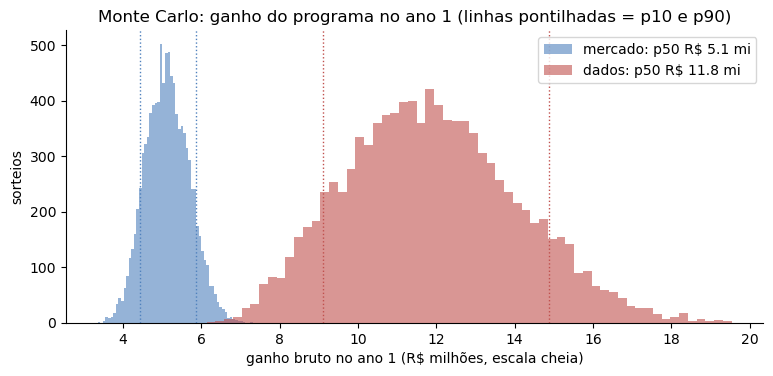

In [4]:
# Histograma: distribuição do ganho do ano 1 nas duas visões (mostra a faixa, não só a média).
fig, ax = plt.subplots(figsize=(9, 3.8))
for v, cor in (("mercado", "#4F81BD"), ("dados", "#C0504D")):
    t = ano1[v].sum(axis=1) / 1e6
    ax.hist(t, bins=60, alpha=0.6, color=cor, label=f"{v}: p50 R$ {t.median():,.1f} mi")
    for p in (0.1, 0.9):
        ax.axvline(t.quantile(p), color=cor, ls=":", lw=1)
ax.set_xlabel("ganho bruto no ano 1 (R$ milhões, escala cheia)"); ax.set_ylabel("sorteios")
ax.set_title("Monte Carlo: ganho do programa no ano 1 (linhas pontilhadas = p10 e p90)"); ax.legend()
savefig(fig, "10b_monte_carlo_ano1", out=PH10)

## 2. O que mais pesa na incerteza
Correlação de postos (Spearman) entre o ganho de cada iniciativa e o ganho total do ano 1: quanto maior,
mais aquela iniciativa decide se o programa vai bem ou mal. É onde vale **refinar a premissa** antes de
prometer o número à diretoria.

In [5]:
sens = pd.DataFrame({v: ano1[v].rank().corrwith(ano1[v].sum(axis=1).rank()) for v in ("dados", "mercado")})
sens["iniciativa"] = inic.iniciativa
sens = sens.sort_values("mercado", ascending=False)
save(sens.reset_index(names="id").round(3), "10b_sensibilidade", out=PH10)
sens.round(2)

,dados,mercado,iniciativa
I01,0.99,0.81,Kit de doca fria + POP-01 (8 docas)
I02,0.08,0.31,Agendamento distribuído de docas
I06,0.07,0.25,Trava de vida útil de 70% no WMS + scorecard F...
I04,0.07,0.23,Carrinho multi-volume no e-commerce (lote de 8)
I05,0.05,0.21,Reabastecimento da face por mínimo (gatilho no...
I07,0.05,0.19,+1 doca fria em cada câmara (após o agendamento)
I03,0.05,0.16,Slotting otimizado das faces (PuLP)
I09,-0.01,0.02,Estoque de segurança e ponto de pedido por SKU
I08,-0.01,0.01,Inventário cíclico por ABC (POP-04)


## 3. Matriz valor × esforço × risco
Gráfico de bolhas: **eixo x = esforço** (1 a 3), **eixo y = ganho em regime p50 na visão de mercado**,
**tamanho = CAPEX** e **cor = risco**. É o formato certo porque mostra as três dimensões da decisão em uma
imagem: o quadrante de cima à esquerda (muito valor, pouco esforço) é a primeira onda.

,iniciativa,esforco,risco,capex,inicio_mes,regime_p50_mercado,regime_p10_mercado,ano1_p50_mercado,regime_p50_dados,prioridade,onda
id,,,,,,,,,,,
I02,Agendamento distribuído de docas,1,baixo,0.00,1,874.00,628.00,837.00,874.00,874.00,Onda 1 (0-3 meses)
I03,Slotting otimizado das faces (PuLP),1,baixo,25.00,2,848.00,713.00,777.00,848.00,848.00,Onda 1 (0-3 meses)
I01,Kit de doca fria + POP-01 (8 docas),2,medio,760.00,2,"2,271.00","1,567.00","1,791.00","10,709.00",757.00,Onda 1 (0-3 meses)
I06,Trava de vida útil de 70% no WMS + scorecard F...,1,medio,0.00,1,736.00,565.00,702.00,735.00,490.00,Onda 1 (0-3 meses)
I05,Reabastecimento da face por mínimo (gatilho no...,1,medio,0.00,3,695.00,482.00,520.00,695.00,463.00,Onda 1 (0-3 meses)
I08,Inventário cíclico por ABC (POP-04),1,baixo,0.00,1,-126.00,-143.00,-126.00,-126.00,-126.00,Onda 1 (0-3 meses)
I04,Carrinho multi-volume no e-commerce (lote de 8),2,medio,148.00,4,825.00,594.00,549.00,825.00,275.00,Onda 2 (3-6 meses)
I09,Estoque de segurança e ponto de pedido por SKU,2,medio,0.00,4,-123.00,-174.00,-77.00,-123.00,-41.00,Onda 2 (3-6 meses)
I07,+1 doca fria em cada câmara (após o agendamento),3,alto,760.00,10,"1,074.00",699.00,123.00,"1,074.00",143.00,Onda 3 (6-12 meses)


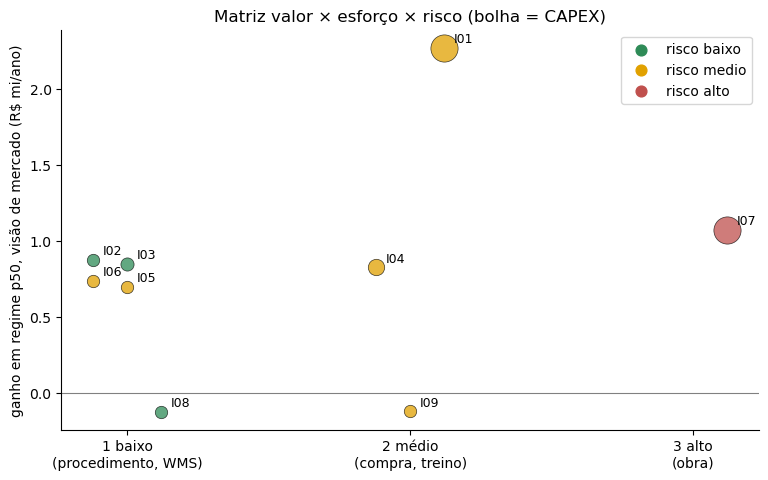

In [6]:
mat = inic[["iniciativa", "esforco", "risco", "capex", "inicio_mes"]].copy()
mat["regime_p50_mercado"] = regime["mercado"].median()
mat["regime_p10_mercado"] = regime["mercado"].quantile(0.10)
mat["ano1_p50_mercado"] = ano1["mercado"].median()
mat["regime_p50_dados"] = regime["dados"].median()
peso_risco = {"baixo": 1.0, "medio": 1.5, "alto": 2.5}
# Índice de prioridade: valor esperado dividido por esforço e risco (simples e explicável)
mat["prioridade"] = mat.regime_p50_mercado / 1e3 / (mat.esforco * mat.risco.map(peso_risco))
ondas = CP["waves"]
mat["onda"] = [next(n for n, (a, b) in ondas.items() if a <= m <= b) for m in mat.inicio_mes]
mat = mat.sort_values(["onda", "prioridade"], ascending=[True, False])
save(mat.reset_index(names="id").round(1), "10b_matriz_prioridade", out=PH10)

cores = {"baixo": "#2E8B57", "medio": "#E1A100", "alto": "#C0504D"}
fig, ax = plt.subplots(figsize=(9, 5.2))
jit = {i: (k % 3 - 1) * 0.12 for k, i in enumerate(mat.index)}
for i, r in mat.iterrows():
    ax.scatter(r.esforco + jit[i], r.regime_p50_mercado / 1e6, s=80 + r.capex / 2500, color=cores[r.risco],
               alpha=0.75, edgecolor="black", lw=0.5)
    ax.annotate(i, (r.esforco + jit[i], r.regime_p50_mercado / 1e6), xytext=(7, 4), textcoords="offset points", fontsize=9)
for nome, cor in cores.items():
    ax.scatter([], [], color=cor, label=f"risco {nome}", s=60)
ax.axhline(0, color="grey", lw=0.8)
ax.set_xticks([1, 2, 3], ["1 baixo\n(procedimento, WMS)", "2 médio\n(compra, treino)", "3 alto\n(obra)"])
ax.set_ylabel("ganho em regime p50, visão de mercado (R$ mi/ano)")
ax.set_title("Matriz valor × esforço × risco (bolha = CAPEX)"); ax.legend(loc="upper right")
savefig(fig, "10b_matriz_valor_esforco", out=PH10)
mat.assign(**{c: mat[c] / 1e3 for c in ["capex", "regime_p50_mercado", "regime_p10_mercado", "ano1_p50_mercado", "regime_p50_dados"]}).round(0)

## 4. Plano em ondas (12 meses)
| Onda | Iniciativas | Lógica |
|---|---|---|
| **1 (0–3 meses)** | I02 agendamento, I06 trava de 70%, I08 inventário cíclico, I03 slotting, I01 kit de doca fria + POP-01, I05 reabastecimento por mínimo | baixo CAPEX, procedimento e configuração de WMS; o kit de doca fria entra já porque é o maior valor nas duas visões |
| **2 (3–6 meses)** | I04 carrinho do e-commerce, I09 ES/PP por SKU | dependem de TI (onda de e-commerce, parâmetros por SKU) e de treinamento |
| **3 (6–12 meses)** | I07 +1 doca fria por câmara | obra de maior risco; só se, após 3 meses de agendamento, a espera de carreta frigorífica continuar acima da meta |

**Habilitadoras sem valor em R$ no total** (entram no plano mesmo assim):
- Telemetria de temperatura + preventiva das câmaras (onda 1): o evento de jan/2026 custou R$ ~20,7 mi.
- 8D com o Fornecedor 010 (onda 1): dois recalls no mesmo SKU (R$ ~1,8 mi/ano).
- FEFO dirigido pelo WMS e POP-03 (onda 2): devoluções por validade curta (R$ ~2,9 mi/ano).
- POP-02 putaway com leitura de endereço e auditoria do turno 2 (onda 1).
- Liquidação de descontinuados e calendário de promoções com aceite do PCP (onda 1).

Saldo acumulado positivo a partir do mês 4; saldo no mês 12: R$ 3.7 mi


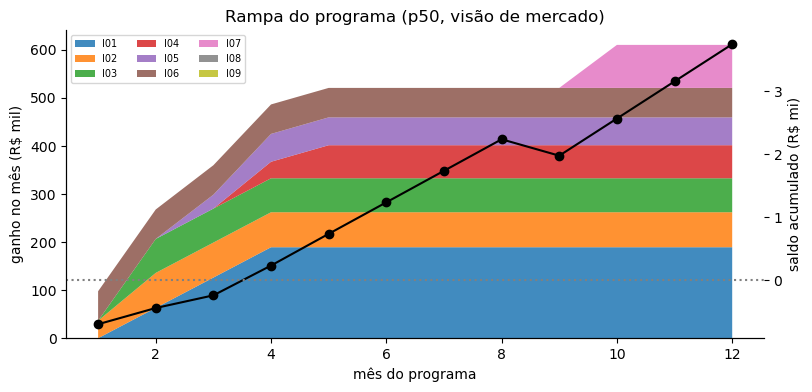

In [7]:
# Curva acumulada mês a mês (p50, visão de mercado): quando o programa se paga
meses = np.arange(1, H + 1)
mensal = pd.DataFrame(index=meses)
for i, cfg in CAT.items():
    f = np.clip((meses - cfg["go_live_month"] + 1) / cfg["ramp_months"], 0, 1)
    mensal[i] = f * mat.loc[i, "regime_p50_mercado"] / 12
capex_mes = pd.Series(0.0, index=meses)
for i, cfg in CAT.items():
    capex_mes[max(cfg["go_live_month"] - 1, 1)] += cfg["capex_brl"]   # compra no mês anterior ao início
acum = (mensal.sum(axis=1) - capex_mes).cumsum()
save(pd.DataFrame({"mes": meses, "ganho_mes": mensal.sum(axis=1), "capex_mes": capex_mes, "saldo_acumulado": acum}).round(0),
     "10b_curva_mensal", out=PH10)
# Área empilhada do ganho mensal por iniciativa + linha do saldo acumulado (mostra a rampa e o payback).
fig, ax = plt.subplots(figsize=(9, 4))
ax.stackplot(meses, (mensal.clip(lower=0) / 1e3).T.values, labels=mensal.columns, alpha=0.85)
ax.set_xlabel("mês do programa"); ax.set_ylabel("ganho no mês (R$ mil)")
ax2 = ax.twinx(); ax2.plot(meses, acum / 1e6, color="black", marker="o", lw=1.5, label="saldo acumulado")
ax2.axhline(0, color="grey", ls=":"); ax2.set_ylabel("saldo acumulado (R$ mi)")
ax.legend(loc="upper left", fontsize=7, ncol=3); ax.set_title("Rampa do programa (p50, visão de mercado)")
savefig(fig, "10b_rampa_mensal", out=PH10)
print(f"Saldo acumulado positivo a partir do mês {int(meses[acum.values > 0][0])}; "
      f"saldo no mês 12: R$ {acum.iloc[-1] / 1e6:,.1f} mi")

## 5. KPIs de acompanhamento
Linha de base medida nos dados do ano-base (escala 10% para percentuais; R$ em escala cheia). As metas são
**propostas** (estimativas) e devem ser validadas com a operação.

In [8]:
lim = P["operations"]["max_dock_exposure_min"]
exp = q("""SELECT zone, AVG(CASE WHEN zone = 'chilled' THEN dock_exposure_min > :lc
                                 ELSE dock_exposure_min > :lf END) AS acima
           FROM fact_receipt WHERE status = 'ACCEPTED' AND zone IN ('chilled', 'frozen')
             AND arrival_ts >= :i AND arrival_ts < :f GROUP BY zone""",
        lc=lim["chilled"], lf=lim["frozen"], i=INI, f=FIM).set_index("zone").acima * 100
vida = q("""SELECT AVG(remaining_life_pct < 70) * 100 AS pct FROM fact_receipt
            WHERE status = 'ACCEPTED' AND arrival_ts >= :i AND arrival_ts < :f""", i=INI, f=FIM).pct[0]
acur = q("""SELECT AVG(counted_sku_id = system_sku_id AND counted_qty_units = system_qty_units) * 100 AS pct
            FROM fact_cycle_count WHERE count_date >= :i AND count_date < :f""", i=INI, f=FIM).pct[0]
fill = q("""SELECT 100.0 * SUM(qty_picked_units) / SUM(qty_ordered_units) AS pct FROM fact_order_line
            WHERE order_date >= :i AND order_date < :f""", i=INI, f=FIM).pct[0]
base10a = pd.read_csv(PH10 / "10a_linha_base.csv", sep=";", decimal=",", header=[0, 1], index_col=0)
seis = pd.read_csv(ROOT / "reports" / "phase6" / "06b_cenarios.csv", sep=";", decimal=",").set_index("cenario")
cinco = pd.read_csv(ROOT / "reports" / "phase5" / "05b_cenarios.csv", sep=";", decimal=",").set_index("cenario")
sete = pd.read_csv(ROOT / "reports" / "phase7" / "07a_produtividade_atual.csv", sep=";", decimal=",")
lph_ecom = sete[sete.channel == "ECOM"].linhas.sum() / sete[sete.channel == "ECOM"].horas.sum()

kpis = pd.DataFrame([
    ("I01", "% paletes resfriados acima de 30 min na doca", exp["chilled"], "≤ 5%", "diário", "Recebimento"),
    ("I01", "% paletes congelados acima de 15 min na doca", exp["frozen"], "≤ 5%", "diário", "Recebimento"),
    ("I01", "Perda por frio (% da receita do frio)", 100 * frio.loc["Total", "frio_dados_mi"] / frio.loc["Total", "receita_mi"], "≤ 1%", "mensal", "Qualidade"),
    ("I02/I07", "Espera p90 da carreta resfriada no pátio (min)", seis.loc["S0 Base", "pátio p90 resfr. (min)"], "≤ 240", "semanal", "Recebimento"),
    ("I03/I05", "% visitas atendidas na face de picking", cinco.loc["Atual", "visitas_na_face_%"], "≥ 85%", "semanal", "Armazenagem"),
    ("I04", "Linhas por hora no e-commerce", lph_ecom, "≥ 90", "diário", "Operações"),
    ("I06", "% paletes aceitos com < 70% de vida útil", vida, "0%", "diário", "Recebimento"),
    ("I08", "Acuracidade de inventário (%)", acur, "≥ 98,5%", "mensal", "Inventário"),
    ("I09", "Fill rate em unidades (%)", fill, "≥ 97%", "semanal", "PCP"),
    ("Programa", "Custo por pedido B2B (R$)", base10a.loc["B2B", ("dados", "por_pedido")], "−10% em 12 meses", "mensal", "Controladoria"),
    ("Programa", "Custo por unidade e-commerce (R$)", base10a.loc["ECOM", ("dados", "por_unidade")], "−25% em 12 meses", "mensal", "Controladoria"),
], columns=["iniciativa", "kpi", "linha_de_base", "meta_proposta", "frequencia", "dono"])
save(kpis.round(2), "10b_kpis_acompanhamento", out=PH10)
kpis.round(1)

,iniciativa,kpi,linha_de_base,meta_proposta,frequencia,dono
0,I01,% paletes resfriados acima de 30 min na doca,27.10,≤ 5%,diário,Recebimento
1,I01,% paletes congelados acima de 15 min na doca,62.70,≤ 5%,diário,Recebimento
2,I01,Perda por frio (% da receita do frio),4.10,≤ 1%,mensal,Qualidade
3,I02/I07,Espera p90 da carreta resfriada no pátio (min),348.30,≤ 240,semanal,Recebimento
4,I03/I05,% visitas atendidas na face de picking,26.40,≥ 85%,semanal,Armazenagem
5,I04,Linhas por hora no e-commerce,34.70,≥ 90,diário,Operações
6,I06,% paletes aceitos com < 70% de vida útil,6.00,0%,diário,Recebimento
7,I08,Acuracidade de inventário (%),95.80,"≥ 98,5%",mensal,Inventário
8,I09,Fill rate em unidades (%),92.40,≥ 97%,semanal,PCP
9,Programa,Custo por pedido B2B (R$),498.70,−10% em 12 meses,mensal,Controladoria


In [9]:
log(NB, f"Monte Carlo {N} sorteios (semente {CP['monte_carlo']['seed']}), triangulares e captura por risco de "
        f"config/cost_program.yaml, iniciativas independentes; horizonte {H} meses; KPIs medidos no ano-base")